# Preparing Stocks

This notebook turns the raw daily price files of every NASDAQ-traded stock into a clean dataset for the analysis chapters.

- **Input:** `data/stocks/<SYMBOL>.csv` (Kaggle *Stock Market Dataset*), with columns `Date, Open, High, Low, Close, Adj Close, Volume`.
- **Output:** `data_processed/stocks_clean.parquet`, one long table with a `Symbol` column. This is the only cleaned version of the stocks; every later notebook reads it.

**Cleaning policy:** a symbol whose series is structurally broken is removed. A single bad value that can be repaired from earlier data is fixed. Rows are never dropped in the middle of a series, because that would leave holes in the time axis.

**Contents**
1. Setup
2. Loading the raw data
3. Date checks
4. Missing values
5. Zero and negative values
6. Cleaning
7. Final check
8. Export

The ETFs go through exactly the same steps in `preparing_etfs.ipynb`. All helper functions live in `src/utils/`.

## 1. Setup

In [1]:
from pathlib import Path

import pandas as pd

from src.utils.loading_data import load_all_symbols
from src.utils.data_inspection import (
    PRICE_VOLUME_COLS,
    date_range_table,
    ends_before,
    get_symbols_with_missing,
    get_symbols_with_negatives,
    get_symbols_with_zeros,
    missing_rates_from_dict,
    symbols_with_unsorted_dates,
    zero_rates_from_dict,
)
from src.utils.data_inspection_viz import (
    plot_missing_counts_over_time,
    plot_start_date_distribution,
    plot_zero_counts_over_time,
)
from src.utils.data_cleaning import (
    add_volatility,
    add_weekday_column,
    fill_zero_open_with_prev_close,
    trim_before_last_nonpositive,
    fill_zero_volumes,
    get_symbols_with_price_jumps,
    remove_symbols,
    trim_leading_zero_volumes,
)
from src.utils.data_export import export_clean_parquet

RAW_DIR = Path("data/stocks")
CUTOFF_DATE = "2020-04-01"  # last date of the Kaggle snapshot

## 2. Loading the raw data

Each CSV is loaded as-is into a dict `{symbol: DataFrame}`. Nothing is cleaned at load time, so every later decision is explicit.

In [2]:
all_stocks = load_all_symbols(RAW_DIR)
n_loaded = len(all_stocks)
print(f"Loaded {n_loaded} stock symbols")

next(iter(all_stocks.values())).head()

Loaded 5884 stock symbols


,Date,Open,High,Low,Close,Adj Close,Volume,Symbol
0,1999-11-18,32.546494,35.765381,28.612303,31.473534,27.068665,62546300,A
1,1999-11-19,30.713520,30.758226,28.478184,28.880543,24.838577,15234100,A
2,1999-11-22,29.551144,31.473534,28.657009,31.473534,27.068665,6577800,A
3,1999-11-23,30.400572,31.205294,28.612303,28.612303,24.607880,5975600,A
4,1999-11-24,28.701717,29.998211,28.612303,29.372318,25.261524,4843200,A


## 3. Date checks

These checks look for stocks with a broken or truncated time axis before any cleaning.

### 3.1 Chronological order

In [3]:
unsorted = symbols_with_unsorted_dates(all_stocks)
print(f"Symbols with dates out of order: {len(unsorted)}", unsorted)

Symbols with dates out of order: 0 []


### 3.2 Date coverage

First date, last date and number of rows for each symbol.

In [4]:
date_ranges = date_range_table(all_stocks)
print(f"Earliest start: {date_ranges['first_date'].min().date()}")
print(f"Latest end:     {date_ranges['last_date'].max().date()}")

date_ranges.sort_values("n_rows").head()

Earliest start: 1962-01-02
Latest end:     2020-04-02


,first_date,last_date,n_rows
symbol,,,
SCA,2020-04-01,2020-04-01,1
RILYP,2020-01-17,2020-04-01,2
METX,2019-10-02,2020-04-01,3
GHIV,2020-03-25,2020-04-01,6
LGF.B,2016-12-09,2016-12-16,6


### 3.3 Symbols that end before the cutoff

The snapshot ends on 2020-04-01, so a series that stops earlier is truncated (for example, a delisted symbol). It can't be compared with the others over the same period, so it is removed.

In [5]:
ended_early = ends_before(all_stocks, "stocks", cutoff_date=CUTOFF_DATE)
all_stocks = remove_symbols(all_stocks, ended_early)
print(f"Removed {len(ended_early)} symbols, {len(all_stocks)} remaining")

 The following stocks end before 2020-04-01:
  - CARR#
  - LGF.B
  - SDPI
  - ZIONW
Removed 4 symbols, 5880 remaining


### 3.4 Start dates

Stocks enter the dataset at very different dates. This is why the later analyses compare symbols over their overlapping periods.

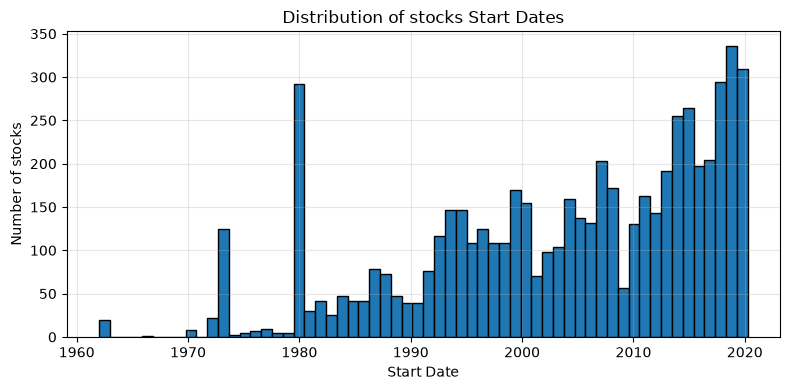

In [6]:
plot_start_date_distribution(all_stocks, "stocks")

### 3.5 Weekday column

`Weekday` (0 = Monday … 4 = Friday) is used by the volume imputation in section 6.7.

In [7]:
add_weekday_column(all_stocks)
next(iter(all_stocks.values())).head(3)

,Date,Weekday,Open,High,Low,Close,Adj Close,Volume,Symbol
0,1999-11-18,3,32.546494,35.765381,28.612303,31.473534,27.068665,62546300,A
1,1999-11-19,4,30.713520,30.758226,28.478184,28.880543,24.838577,15234100,A
2,1999-11-22,0,29.551144,31.473534,28.657009,31.473534,27.068665,6577800,A


## 4. Missing values

All rates are computed on the six raw columns `Open, High, Low, Close, Adj Close, Volume`.

### 4.1 Missing rates

In [8]:
missing_per_symbol, missing_overall = missing_rates_from_dict(all_stocks)
missing_overall

,Total Missing Rate (%)
Open,0.002683
High,0.002683
Low,0.002683
Close,0.002683
Adj Close,0.002683
Volume,0.002683


### 4.2 Missing values over time

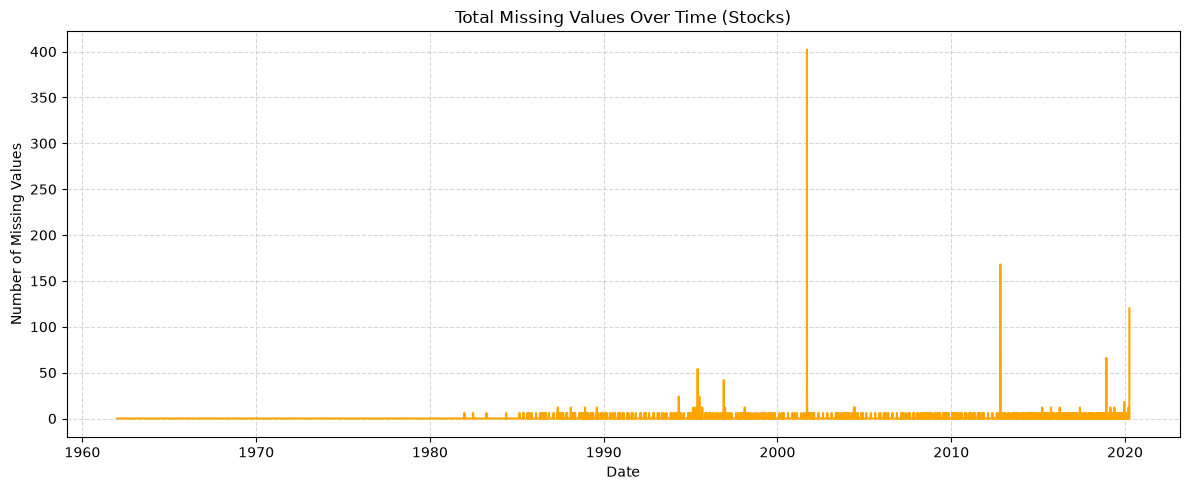

In [9]:
_ = plot_missing_counts_over_time(all_stocks, label="Stocks")

### 4.3 Which symbols are affected?

In [10]:
missing_by_col = {col: get_symbols_with_missing(all_stocks, col) for col in PRICE_VOLUME_COLS}
for col, syms in missing_by_col.items():
    print(f"{col:<10} {len(syms):>4} symbols")

same_symbols = all(set(syms) == set(missing_by_col["Open"]) for syms in missing_by_col.values())
print("\nSame symbols in every column:", same_symbols)

Open        256 symbols
High        256 symbols
Low         256 symbols
Close       256 symbols
Adj Close   256 symbols
Volume      256 symbols

Same symbols in every column: True


The NaNs sit in exactly the same symbols for every column. They come from whole broken rows, not from scattered gaps.

### 4.4 Remove symbols with missing values

Filling these gaps would mean inventing whole stretches of prices, and only a small share of symbols is affected (about 4% of stocks). So these symbols are removed.

In [11]:
missing_symbols = sorted(set().union(*missing_by_col.values()))
n_before = len(all_stocks)
all_stocks = remove_symbols(all_stocks, missing_symbols)
print(f"Removed {len(missing_symbols)} symbols ({len(missing_symbols) / n_before:.2%}), {len(all_stocks)} remaining")

Removed 256 symbols (4.35%), 5624 remaining


## 5. Zero and negative values

A price of 0 or below is a data error. A volume of 0 is suspicious too, but it can be repaired from earlier days.

### 5.1 Zero rates

Only the raw price/volume columns are checked. `Weekday` (0 = Monday) and `Volatility` (0 when High = Low) can legitimately be 0, so they are left out.

In [12]:
zero_per_symbol, zero_overall = zero_rates_from_dict(all_stocks)
zero_overall

,Total Zero Rate (%)
Open,4.505312
High,0.000081
Low,0.000081
Close,0.000076
Adj Close,0.000076
Volume,5.781440


### 5.2 Zeros over time

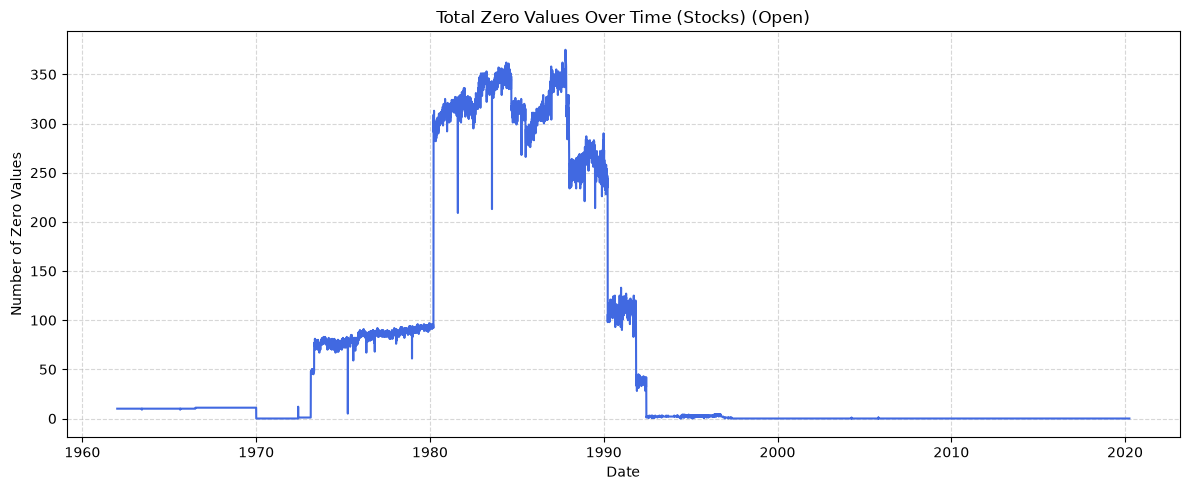

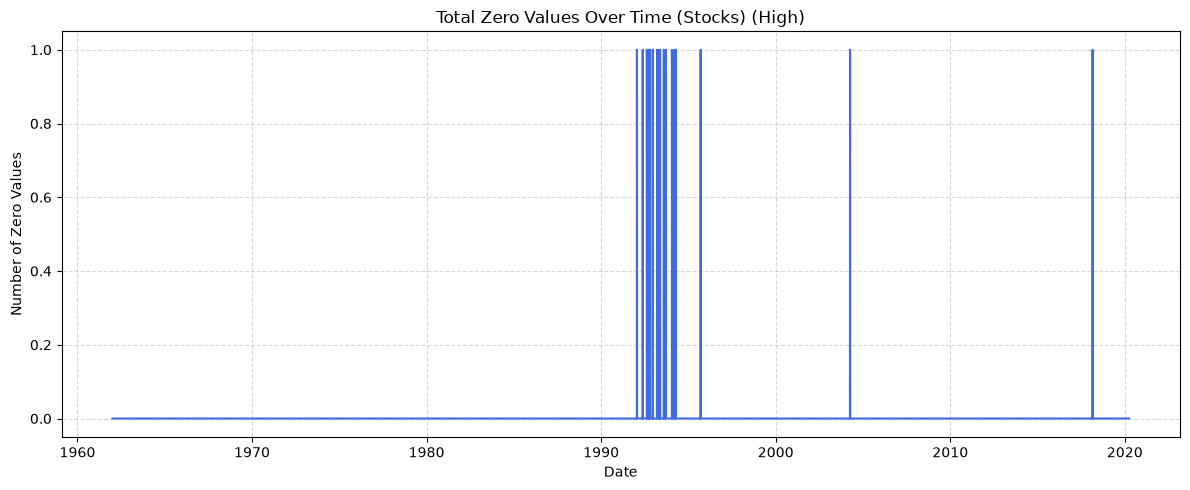

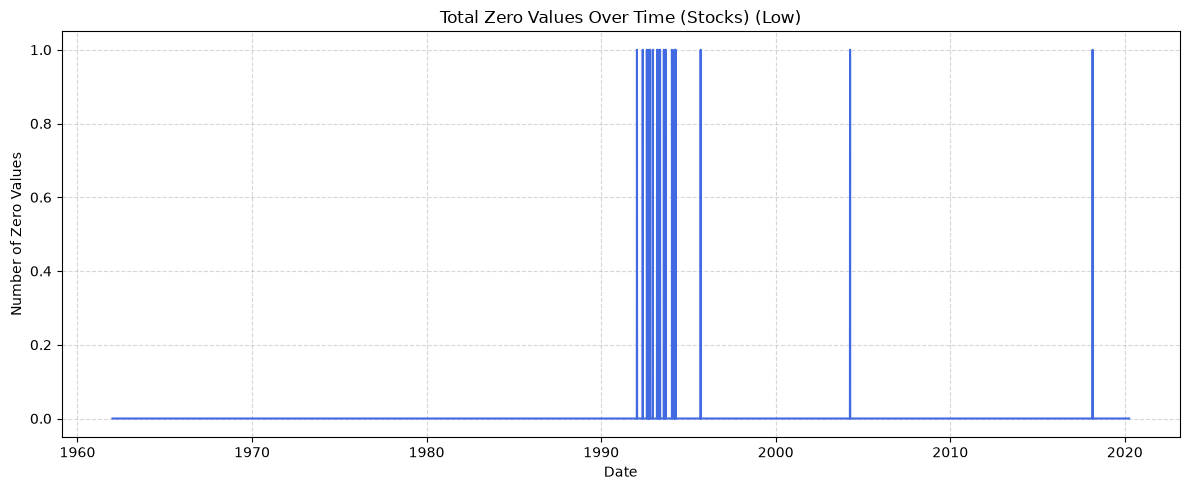

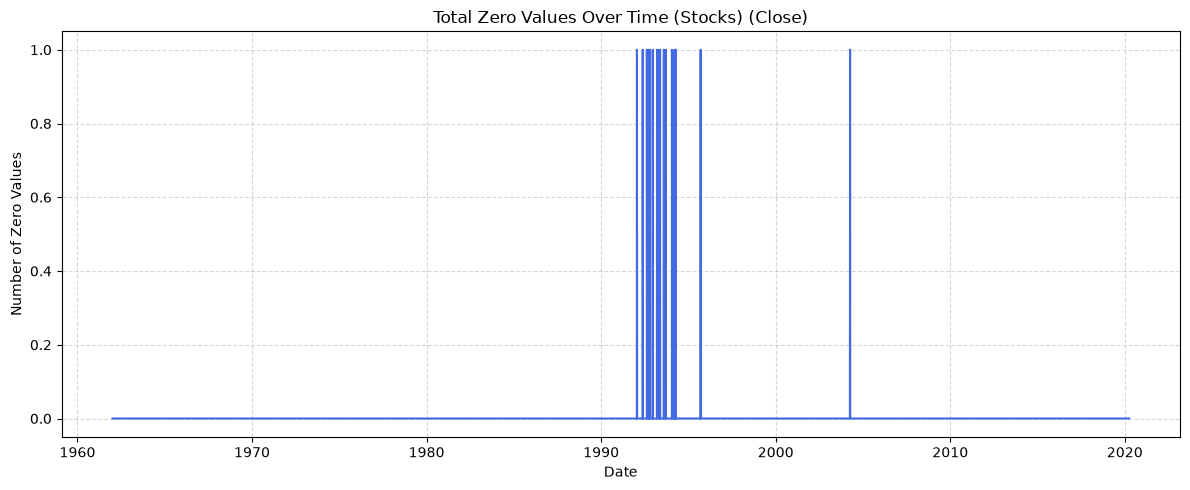

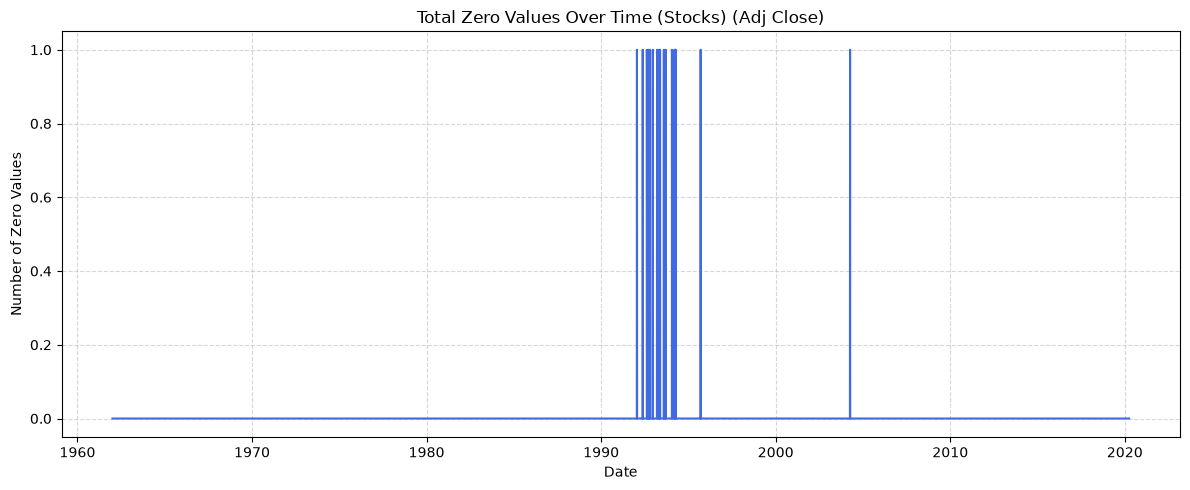

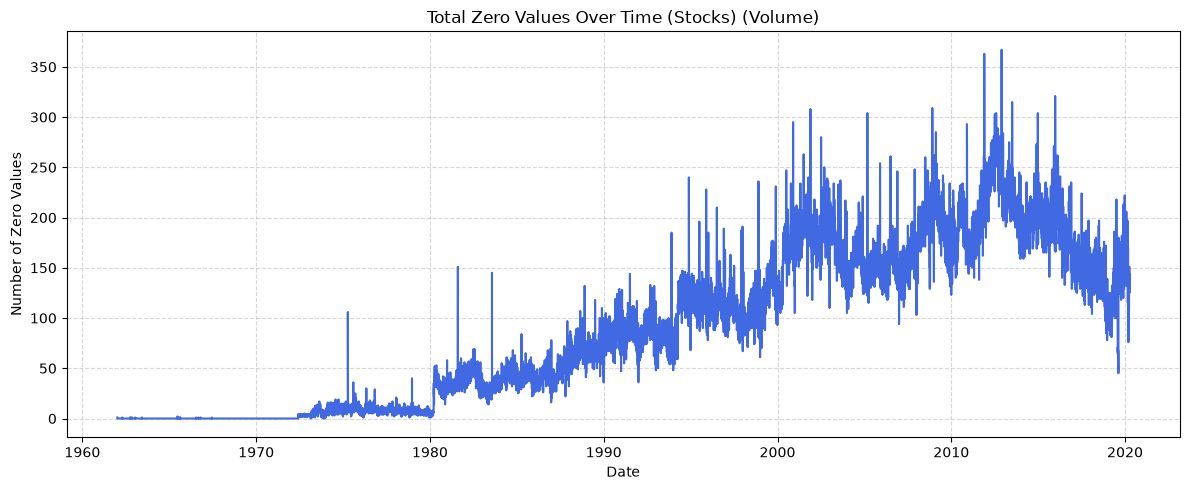

In [13]:
for col in PRICE_VOLUME_COLS:
    _ = plot_zero_counts_over_time(all_stocks, label="Stocks", column=col)

### 5.3 Which symbols are affected?

In [14]:
zero_by_col = {col: get_symbols_with_zeros(all_stocks, col) for col in PRICE_VOLUME_COLS}
for col, syms in zero_by_col.items():
    preview = ", ".join(syms[:10]) + (" ..." if len(syms) > 10 else "")
    print(f"{col:<10} {len(syms):>5} symbols  {preview}")

Open         714 symbols  AAME, AAN, AB, ABM, ABMD, ABT, ACU, ADBE, ADI, ADM ...
High          13 symbols  APEX, ASYS, AXDX, HWKN, KERN, MAYS, NEOG, NRIM, PMD, PNRG ...
Low           13 symbols  APEX, ASYS, AXDX, HWKN, KERN, MAYS, NEOG, NRIM, PMD, PNRG ...
Close         12 symbols  APEX, ASYS, AXDX, HWKN, MAYS, NEOG, NRIM, PMD, PNRG, RMCF ...
Adj Close     12 symbols  APEX, ASYS, AXDX, HWKN, MAYS, NEOG, NRIM, PMD, PNRG, RMCF ...
Volume      3181 symbols  AA, AAMC, AAME, AAN, AAON, AAWW, ABCB, ABEO, ABEV, ABIO ...


Zeros in `High`, `Low`, `Close` or `Adj Close` affect only a handful of symbols and mean the whole series is unreliable. Zeros in `Open` and `Volume` are much more common, and section 6 repairs them.

### 5.4 Negative values

A negative raw price (`Open`, `High`, `Low`, `Close`) or volume is impossible, so a symbol with one is treated as corrupted.

A negative `Adj Close` is different: it is a known Yahoo artifact. `Adj Close` is the price adjusted backwards for all later dividends, and for very old dates of high-dividend stocks the adjustment can push it to zero or below, while the rest of the history is valid. Those series are cut instead of removed (section 6.2).

In [15]:
negative_by_col = {col: get_symbols_with_negatives(all_stocks, col) for col in PRICE_VOLUME_COLS}
for col, syms in negative_by_col.items():
    print(f"{col:<10} {len(syms):>5} symbols  {', '.join(syms[:10])}")

Open           0 symbols  
High           0 symbols  
Low            0 symbols  
Close          0 symbols  
Adj Close     12 symbols  AAN, CASS, ERIC, ICL, ITRN, NVO, SAN, SEE, SID, SQM
Volume         0 symbols  


## 6. Cleaning

### 6.1 Remove corrupted symbols

Symbols with a zero `High`, `Low`, `Close` or `Adj Close`, or with a negative raw price or volume, are removed.

In [16]:
corrupted = sorted(
    set().union(*(zero_by_col[col] for col in ["High", "Low", "Close", "Adj Close"]))
    | set().union(*(negative_by_col[col] for col in ["Open", "High", "Low", "Close", "Volume"]))
)
all_stocks = remove_symbols(all_stocks, corrupted)
print(f"Removed {len(corrupted)} symbols: {corrupted}")
print(f"{len(all_stocks)} remaining")

Removed 13 symbols: ['APEX', 'ASYS', 'AXDX', 'HWKN', 'KERN', 'MAYS', 'NEOG', 'NRIM', 'PMD', 'PNRG', 'RMCF', 'SEED', 'STRL']
5611 remaining


### 6.2 Cut histories that start with a non-positive `Adj Close`

Each affected series now starts the day after its last non-positive `Adj Close`, so it stays one continuous series.

In [17]:
trimmed = trim_before_last_nonpositive(all_stocks, column="Adj Close")
print(f"Cut the start of {len(trimmed)} symbols: {trimmed}")

Cut the start of 12 symbols: ['AAN', 'CASS', 'ERIC', 'ICL', 'ITRN', 'NVO', 'SAN', 'SEE', 'SID', 'SQM', 'UGP', 'UN']


### 6.3 Remove symbols with impossible price jumps

`Close` is already adjusted for splits, so a move of more than ×5 (or below ÷5) in one day is not a real price move. It usually means the ticker belonged to another security before: for example data going back years before the company listed, with prices jumping between 3 and 25,000. These prices would also give the symbol a huge dollar volume, so they would dominate any volume-weighted average. Such symbols are removed.

In [18]:
price_jumps = get_symbols_with_price_jumps(all_stocks, column="Close", max_ratio=5)
all_stocks = remove_symbols(all_stocks, price_jumps)
print(f"Removed {len(price_jumps)} symbols: {price_jumps}")
print(f"{len(all_stocks)} remaining")

Removed 348 symbols: ['AC', 'ACB', 'ACER', 'ACHV', 'ADXN', 'AGX', 'AIM', 'AIO', 'AIRI', 'AIRTP', 'AJXA', 'AKCA', 'AKTX', 'ALACR', 'ALC', 'ALIM', 'ALO', 'ALT', 'AMCI', 'AMEH', 'AMK', 'AMPY', 'AMRH', 'ANVS', 'APM', 'AQB', 'AQN', 'ARA', 'ARAV', 'ARCH', 'ARD', 'AREC', 'ARTW', 'ARWR', 'ATCO', 'ATV', 'AVTR', 'AXO', 'AYTU', 'BFC', 'BGI', 'BHAT', 'BHF', 'BHR', 'BILL', 'BIMI', 'BKI', 'BLBD', 'BLD', 'BLNK', 'BLPH', 'BLU', 'BNGO', 'BPMX', 'BRPAR', 'BRY', 'BST', 'BW', 'CAI', 'CASS', 'CBH', 'CC', 'CCAP', 'CCB', 'CCD', 'CCX', 'CETV', 'CFB', 'CGA', 'CHRS', 'CIA', 'CIH', 'CLAR', 'CLRB', 'CLSK', 'CLSN', 'CMRX', 'CNET', 'CNF', 'COCP', 'CODA', 'COE', 'CPAH', 'CPHI', 'CRC', 'CREG', 'CTAA', 'CTK', 'CTRC', 'CTZ', 'CUBB', 'CXDC', 'DAO', 'DCF', 'DFFN', 'DLPN', 'DMAC', 'DNK', 'DOMO', 'DRIO', 'DS', 'DTIL', 'DTP', 'DTY', 'DUOT', 'DVAX', 'EAF', 'EE', 'EFL', 'EHC', 'EHT', 'EIC', 'EIGR', 'ELA', 'ELJ', 'EMP', 'EPSN', 'EQ', 'ERI', 'ETON', 'EVFM', 'FHB', 'FHI', 'FINS', 'FITBP', 'FIV', 'FLNG', 'FLOW', 'FRHC', 'FSB', 'F

### 6.4 Repair zero `Open` prices

A zero `Open` is replaced by the **previous day's `Close`**, since the open is usually close to yesterday's close. `Open` and `Close` are on the same price basis (adjusted for splits only). `Adj Close` would not be a valid substitute: it is also adjusted for dividends, so on older data it can sit well below `Close`.

If the first row of a series has a zero `Open`, there is no previous day to use, so that row is dropped.

In [19]:
fill_zero_open_with_prev_close(all_stocks)

### 6.5 Trim leading zero-volume days

Rows at the start of a series are dropped until the first non-zero `Volume`. These are usually days before the symbol really started trading.

In [20]:
trim_leading_zero_volumes(all_stocks)

### 6.6 Intraday volatility

`Volatility = (High − Low) / Open` is the normalised daily price range. It scales the imputed volumes below and is kept in the output.

In [21]:
add_volatility(all_stocks)

### 6.7 Impute the remaining zero volumes

For each zero-volume day:

- **baseline** = median of the last 10 non-zero volumes on the same weekday, using earlier days only (if there are none, the last 10 non-zero volumes on any day);
- **volume** = baseline × max(0.01, 1 + 0.7 × z), where z is that day's `Volatility` z-score over the symbol's history.

A wider price range than usual means a higher volume than usual (the volume–volatility relationship).

In [22]:
fill_zero_volumes(all_stocks, n_same_weekday=10, vol_weight=0.7)

### 6.8 Remove symbols that still have zero volume

A zero volume with no earlier non-zero volume can't be imputed.

In [23]:
still_zero = get_symbols_with_zeros(all_stocks, "Volume")
all_stocks = remove_symbols(all_stocks, still_zero)
print(f"Removed {len(still_zero)} symbols: {still_zero}")

Removed 1 symbols: ['GHIV']


## 7. Final check

Both rates should now be 0 in every column.

In [24]:
_, missing_overall = missing_rates_from_dict(all_stocks)
_, zero_overall = zero_rates_from_dict(all_stocks)
pd.concat([missing_overall, zero_overall], axis=1)

,Total Missing Rate (%),Total Zero Rate (%)
Open,0.0,0.0
High,0.0,0.0
Low,0.0,0.0
Close,0.0,0.0
Adj Close,0.0,0.0
Volume,0.0,0.0


In [25]:
print(f"Symbols loaded: {n_loaded}")
print(f"Symbols kept:   {len(all_stocks)} ({len(all_stocks) / n_loaded:.1%})")

Symbols loaded: 5884
Symbols kept:   5262 (89.4%)


## 8. Export

`data_processed/stocks_clean.parquet`: all symbols in one long table, sorted by `Symbol` and `Date`, with the raw columns plus `Weekday`, `Symbol` and `Volatility` (intraday range).

In [26]:
stocks_clean = export_clean_parquet(all_stocks, parquet_name="stocks_clean.parquet")
print(f"Date range: {stocks_clean['Date'].min().date()} → {stocks_clean['Date'].max().date()}")

Saved data_processed/stocks_clean.parquet: 5262 symbols, 21,056,913 rows
Date range: 1962-01-02 → 2020-04-01
